<a href="https://colab.research.google.com/github/AlbertP97/Med-VQA-Survey/blob/main/MedFrameVQA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MedFrameVQA Dataset Analysis

This notebook analyzes the MedFrameVQA dataset for the doctoral research project (Paper 2).

## Dataset Overview
MedFrameVQA is a medical visual question answering dataset with structured metadata.

## 1. Import Libraries

In [1]:
import json
from pathlib import Path
from typing import Iterable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 2. Data Loading

In [2]:
from google.colab import files
import json
import pandas as pd

# Select and load the file from the computer
uploaded_files = files.upload()

# Get the name of the uploaded file
file_name = next(iter(uploaded_files))

# Read the JSON file
json_data = json.loads(uploaded_files[file_name].decode('utf-8'))

# Convert it to a DataFrame
df = pd.DataFrame(json_data)

Saving MedFrameVQA.json to MedFrameVQA.json


In [3]:
variables = [
    'question_id',
    'system',
    'organ',
    'modality',
    'question',
    'answer',
    'options',
    'reasoning_chain'
]

df = df[variables]
df['system'] = (
    df['system']
    .astype(str)
    .str.replace('_', ' ', regex=False)
    .str.replace(r'(?i)\bsystem\b', '', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

print('Dataset loaded successfully')
print(f'Number of records: {len(df)}')
print(f'Number of columns: {len(df.columns)}')
print('Allowed variables in MedFrameVQA:')
for var in variables:
    print(f'  - {var}')

Dataset loaded successfully
Number of records: 2851
Number of columns: 8
Allowed variables in MedFrameVQA:
  - question_id
  - system
  - organ
  - modality
  - question
  - answer
  - options
  - reasoning_chain


## 3. Exploratory Data Analysis

The following sections present dataset distributions and descriptive statistics.

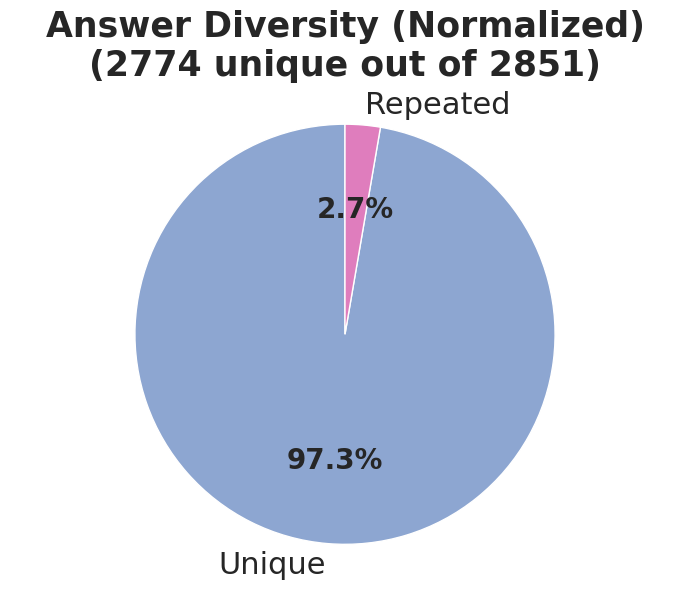

In [4]:
# ============================================================
# FIGURE 1: NORMALIZED ANSWER DIVERSITY
# MedFrameVQA
# ============================================================

# Normalize the answers
normalized_answers = (
    df['answer']
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Remove empty answers
normalized_answers = normalized_answers[
    normalized_answers != ''
]

# Calculate counts
total_answers = len(normalized_answers)
unique_answers = normalized_answers.nunique()
repeated_answers = total_answers - unique_answers

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

wedges, texts, percentages = ax.pie(
    [unique_answers, repeated_answers],
    labels=['Unique', 'Repeated'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#8DA6D1', '#DF7DBD'],
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1
    },
    textprops={
        'fontsize': 22
    }
)

# Format only the percentages
for percentage in percentages:
    percentage.set_fontsize(20)
    percentage.set_fontweight('bold')

ax.set_title(
    f'Answer Diversity (Normalized)\n'
    f'({unique_answers} unique out of {total_answers})',
    fontsize=25,
    fontweight='bold',
    pad=20
)

ax.axis('equal')

plt.tight_layout()
plt.show()

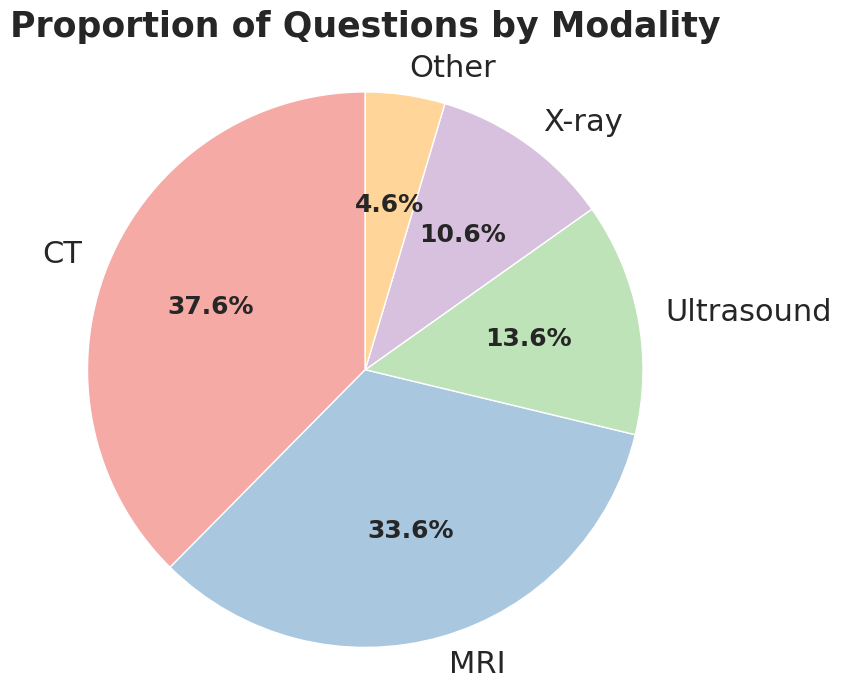

In [5]:
# ============================================================
# FIGURE 2: PROPORTION OF QUESTIONS BY MODALITY
# MedFrameVQA
# ============================================================

# Normalize the modalities
modalities = (
    df['modality']
    .fillna('other')
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace('_', ' ', regex=False)
    .str.replace(r'\s+', ' ', regex=True)
)

# Standardize equivalent names
modalities = modalities.replace({
    'ct scan': 'CT',
    'computed tomography': 'CT',
    'ct': 'CT',

    'magnetic resonance imaging': 'MRI',
    'mr': 'MRI',
    'mri': 'MRI',

    'ultrasound': 'Ultrasound',
    'ultrasonography': 'Ultrasound',
    'us': 'Ultrasound',

    'xray': 'X-ray',
    'x ray': 'X-ray',
    'x-ray': 'X-ray',
    'radiograph': 'X-ray',

    'other': 'Other',
    'unknown': 'Other',
    'none': 'Other',
    'nan': 'Other'
})

# Convert unrecognized modalities to "Other"
allowed_categories = [
    'CT',
    'MRI',
    'Ultrasound',
    'X-ray',
    'Other'
]

modalities = modalities.where(
    modalities.isin(allowed_categories),
    'Other'
)

# Calculate counts and set the order
modality_counts = (
    modalities
    .value_counts()
    .reindex(allowed_categories, fill_value=0)
)

# Remove categories without records
modality_counts = modality_counts[
    modality_counts > 0
]

# Create figure
fig, ax = plt.subplots(figsize=(8, 7))

wedges, texts, percentages = ax.pie(
    modality_counts.values,
    labels=modality_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=[
        '#F6AAA6',
        '#A9C7DF',
        '#BFE3B8',
        '#D7C1DF',
        '#FFD59A'
    ],
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1
    },
    textprops={
        'fontsize': 22
    }
)

# Format only the percentages
for percentage in percentages:
    percentage.set_fontsize(18)
    percentage.set_fontweight('bold')

ax.set_title(
    'Proportion of Questions by Modality',
    fontsize=25,
    fontweight='bold',
    pad=20
)

ax.axis('equal')

plt.tight_layout()
plt.show()

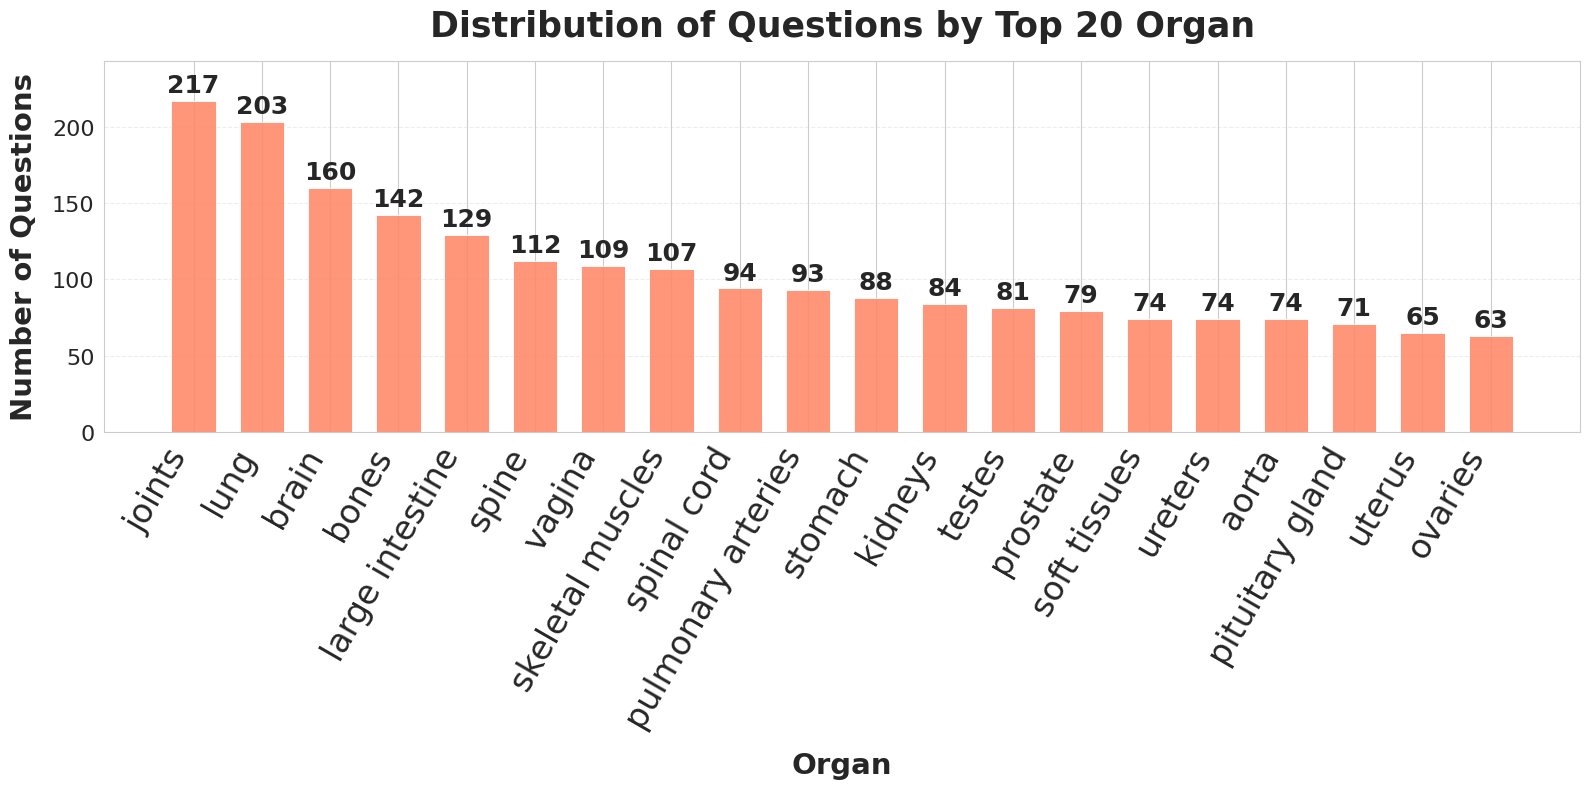

In [6]:
# ============================================================
# FIGURE 3: DISTRIBUTION OF QUESTIONS BY ORGAN
# MedFrameVQA
# ============================================================

# Normalize the organ names
organs = (
    df['organ']
    .fillna('Unknown')
    .astype(str)
    .str.replace('_', ' ', regex=False)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
    .str.lower()
)

# Remove empty or unknown values
organs = organs[
    ~organs.isin([
        '',
        'unknown',
        'nan',
        'none'
    ])
]

# Calculate frequencies in descending order
organ_counts = organs.value_counts().head(20)

# Create positions
positions = np.arange(len(organ_counts))

# Create figure
fig, ax = plt.subplots(figsize=(16, 8))

bars = ax.bar(
    positions,
    organ_counts.values,
    width=0.65,
    color='#FF8A6B',
    edgecolor='white',
    linewidth=0.7,
    alpha=0.9
)

# Place the organ names
ax.set_xticks(positions)

ax.set_xticklabels(
    organ_counts.index,
    rotation=60,
    ha='right',
    fontsize=24
)

# Display the value above each bar
offset = max(organ_counts.values) * 0.012

for bar, value in zip(bars, organ_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + offset,
        f'{value}',
        ha='center',
        va='bottom',
        fontsize=18,
        fontweight='bold'
    )

ax.set_title(
    'Distribution of Questions by Top 20 Organ',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Organ',
    fontsize=21,
    fontweight='bold',
    labelpad=12
)

ax.set_ylabel(
    'Number of Questions',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.tick_params(
    axis='y',
    labelsize=16
)

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.35
)

# Leave space for the values
ax.set_ylim(
    0,
    max(organ_counts.values) * 1.12
)

plt.tight_layout()
plt.show()

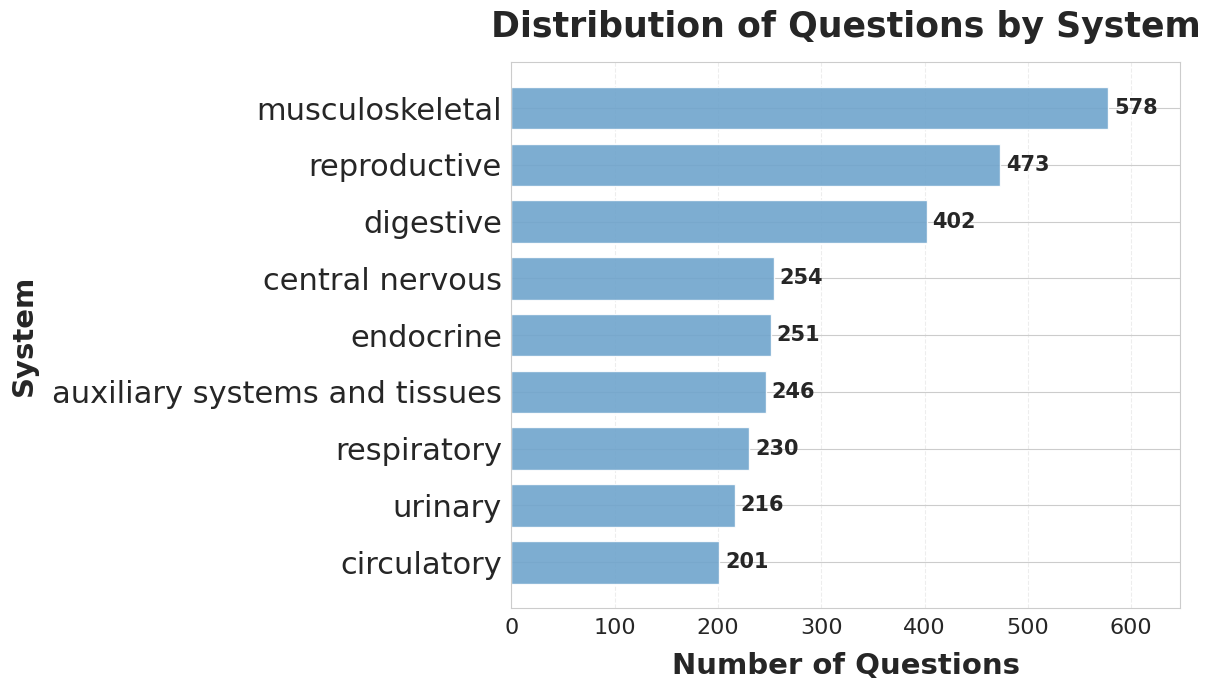

In [7]:
# ============================================================
# FIGURE 4: DISTRIBUTION OF QUESTIONS BY SYSTEM
# MedFrameVQA
# ============================================================

# Normalize the system names
systems = (
    df['system']
    .fillna('Unknown')
    .astype(str)
    .str.replace('_', ' ', regex=False)
    .str.replace(r'(?i)\bsystem\b', '', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
    .str.lower()
)

# Remove empty or unknown values
systems = systems[
    ~systems.isin([
        '',
        'unknown',
        'nan',
        'none'
    ])
]

# Calculate frequencies
system_counts = (
    systems
    .value_counts()
)

# Positions to keep the bars close together
positions = np.arange(len(system_counts)) * 0.60

# Create figure
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    positions,
    system_counts.values,
    color='#6FA4CC',
    height=0.45,
    alpha=0.9
)

# Place the system names
ax.set_yticks(positions)

ax.set_yticklabels(
    system_counts.index,
    fontsize=22
)

ax.invert_yaxis()

# Display the value at the end of each bar
offset = max(system_counts.values) * 0.01

for bar, value in zip(bars, system_counts.values):
    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f'{value}',
        va='center',
        ha='left',
        fontsize=15,
        fontweight='bold'
    )

ax.set_title(
    'Distribution of Questions by System',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Number of Questions',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel(
    'System',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.tick_params(
    axis='x',
    labelsize=16
)

ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.35
)

# Leave space to display the values
ax.set_xlim(
    0,
    max(system_counts.values) * 1.12
)

plt.tight_layout()
plt.show()

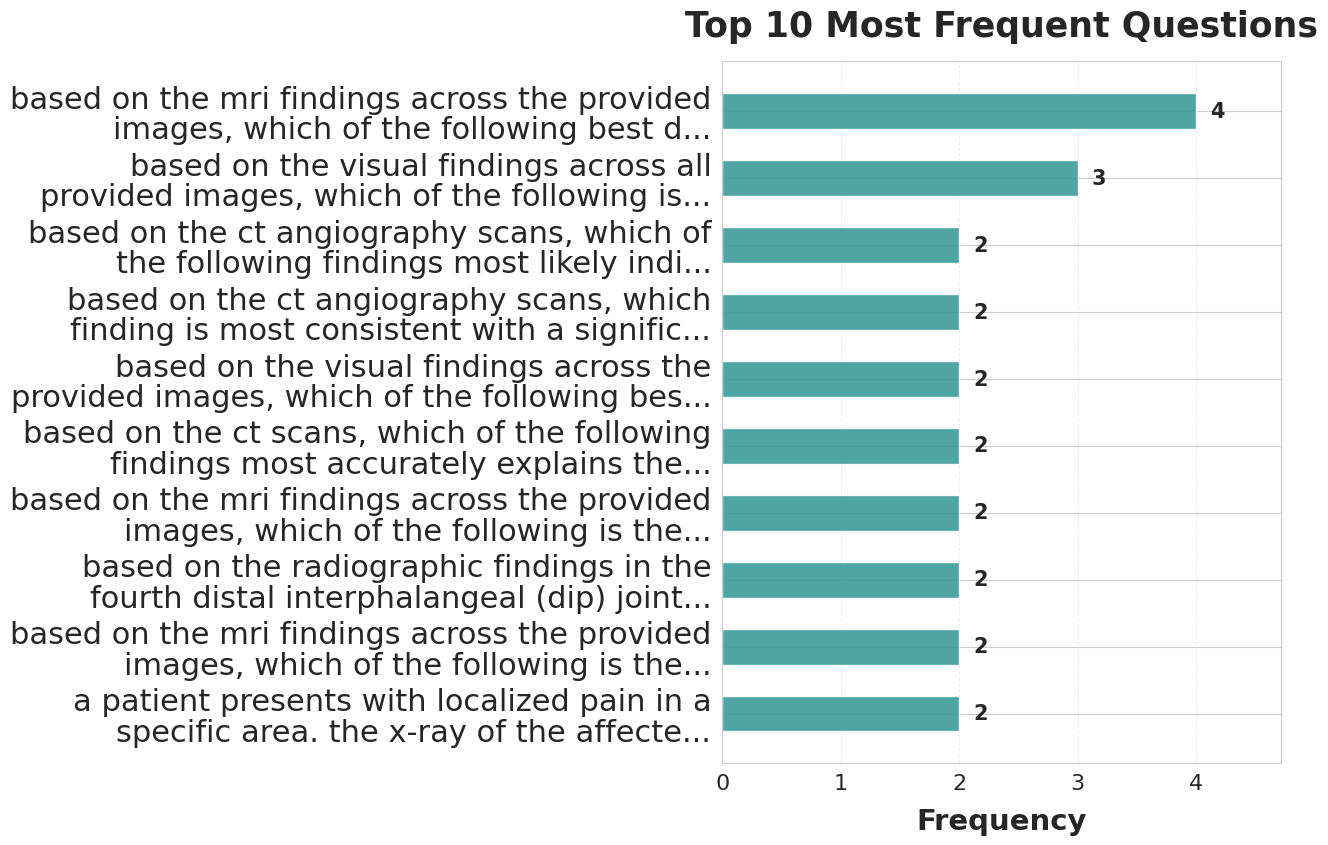

In [8]:
# ============================================================
# FIGURE 5: TOP 10 MOST FREQUENT QUESTIONS
# MedFrameQA
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator

# Normalize the questions
normalized_questions = (
    df['question']
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Remove empty questions
normalized_questions = normalized_questions[
    normalized_questions != ''
]

# Get the 10 most frequent questions
top_questions = (
    normalized_questions
    .value_counts()
    .head(10)
)

# Split long questions into a maximum of two lines
def split_into_two_lines(text, max_characters=86):
    """Split text into at most two lines near its midpoint.

    Args:
        text: The text to split.
        max_characters: The maximum number of characters to retain.

    Returns:
        The shortened text on one or two lines.
    """
    if len(text) > max_characters:
        text = text[:max_characters - 3].rstrip() + '...'

    if len(text) <= 43:
        return text

    # Find a space near the midpoint
    midpoint = len(text) // 2
    spaces = [
        i for i, character in enumerate(text)
        if character == ' '
    ]

    split_point = min(
        spaces,
        key=lambda position: abs(position - midpoint)
    )

    return (
        text[:split_point].strip()
        + '\n'
        + text[split_point + 1:].strip()
    )

question_labels = [
    split_into_two_lines(question)
    for question in top_questions.index
]

# Greater vertical spacing for two-line labels
positions = np.arange(len(top_questions)) * 0.85

# Narrower figure
fig, ax = plt.subplots(figsize=(13, 9))

bars = ax.barh(
    positions,
    top_questions.values,
    color='#3A9D9A',
    height=0.45,
    alpha=0.9
)

ax.set_yticks(positions)

ax.set_yticklabels(
    question_labels,
    fontsize=22,
    linespacing=1.05
)

ax.invert_yaxis()

# Display the value at the end of each bar
offset = max(top_questions.values) * 0.03

for bar, value in zip(bars, top_questions.values):
    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f'{value}',
        va='center',
        ha='left',
        fontsize=15,
        fontweight='bold'
    )

ax.set_title(
    'Top 10 Most Frequent Questions',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel('')

ax.tick_params(
    axis='x',
    labelsize=16
)

ax.tick_params(
    axis='y',
    length=0,
    pad=8
)

ax.xaxis.set_major_locator(
    MaxNLocator(integer=True)
)

ax.set_axisbelow(True)

ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.35
)

ax.set_xlim(
    0,
    max(top_questions.values) * 1.18
)

plt.subplots_adjust(
    left=0.53,
    right=0.96,
    top=0.90,
    bottom=0.12
)

plt.show()

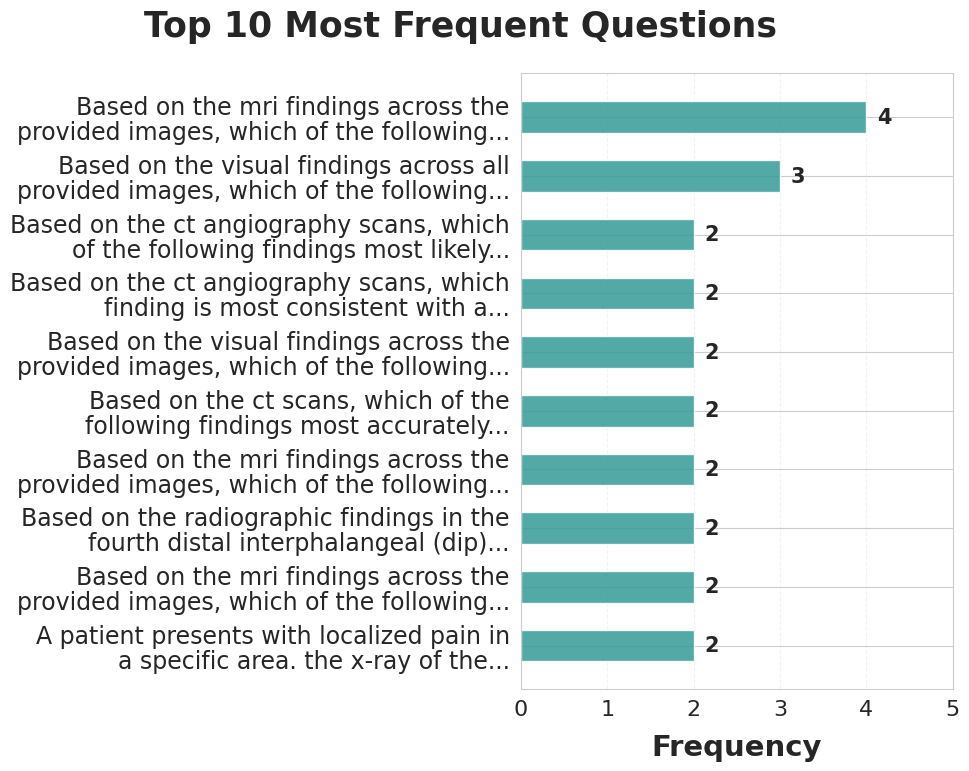

In [9]:
# ============================================================
# FIGURE 5: TOP 10 MOST FREQUENT QUESTIONS
# MedFrameQA
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import textwrap
from matplotlib.ticker import MaxNLocator

# Normalize the questions
normalized_questions = (
    df['question']
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

normalized_questions = normalized_questions[
    normalized_questions != ''
]

# Get the 10 most frequent questions
top_questions = (
    normalized_questions
    .value_counts()
    .head(10)
)

# Shorten and split each question into a maximum of two lines
def format_question(question, width=42, max_characters=82):
    """Format a question into a shortened, wrapped label.

    Args:
        question: The question to format.
        width: The maximum line width.
        max_characters: The maximum text length before wrapping.

    Returns:
        The formatted question label.
    """
    question = question.capitalize()

    text = textwrap.shorten(
        question,
        width=max_characters,
        placeholder='...'
    )

    return textwrap.fill(
        text,
        width=width,
        break_long_words=False,
        break_on_hyphens=False,
        max_lines=2,
        placeholder='...'
    )

question_labels = [
    format_question(question)
    for question in top_questions.index
]

# Vertical spacing
positions = np.arange(len(top_questions)) * 0.78

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    positions,
    top_questions.values,
    height=0.42,
    color='#3A9D9A',
    alpha=0.88
)

ax.set_yticks(positions)

ax.set_yticklabels(
    question_labels,
    fontsize=17,
    ha='right',
    linespacing=1.05
)

ax.invert_yaxis()

# Values at the end of the bars
offset = max(top_questions.values) * 0.03

for bar, value in zip(bars, top_questions.values):
    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f'{value}',
        va='center',
        ha='left',
        fontsize=15,
        fontweight='bold'
    )

# Title centered over the entire figure
fig.suptitle(
    'Top 10 Most Frequent Questions',
    fontsize=25,
    fontweight='bold',
    y=0.97
)

ax.set_xlabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel('')

ax.tick_params(
    axis='x',
    labelsize=16
)

ax.tick_params(
    axis='y',
    length=0,
    pad=8
)

ax.xaxis.set_major_locator(
    MaxNLocator(integer=True)
)

ax.set_axisbelow(True)

ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.25
)

ax.set_xlim(
    0,
    max(top_questions.values) * 1.25
)

plt.subplots_adjust(
    left=0.55,
    right=0.91,
    top=0.89,
    bottom=0.12
)

plt.show()

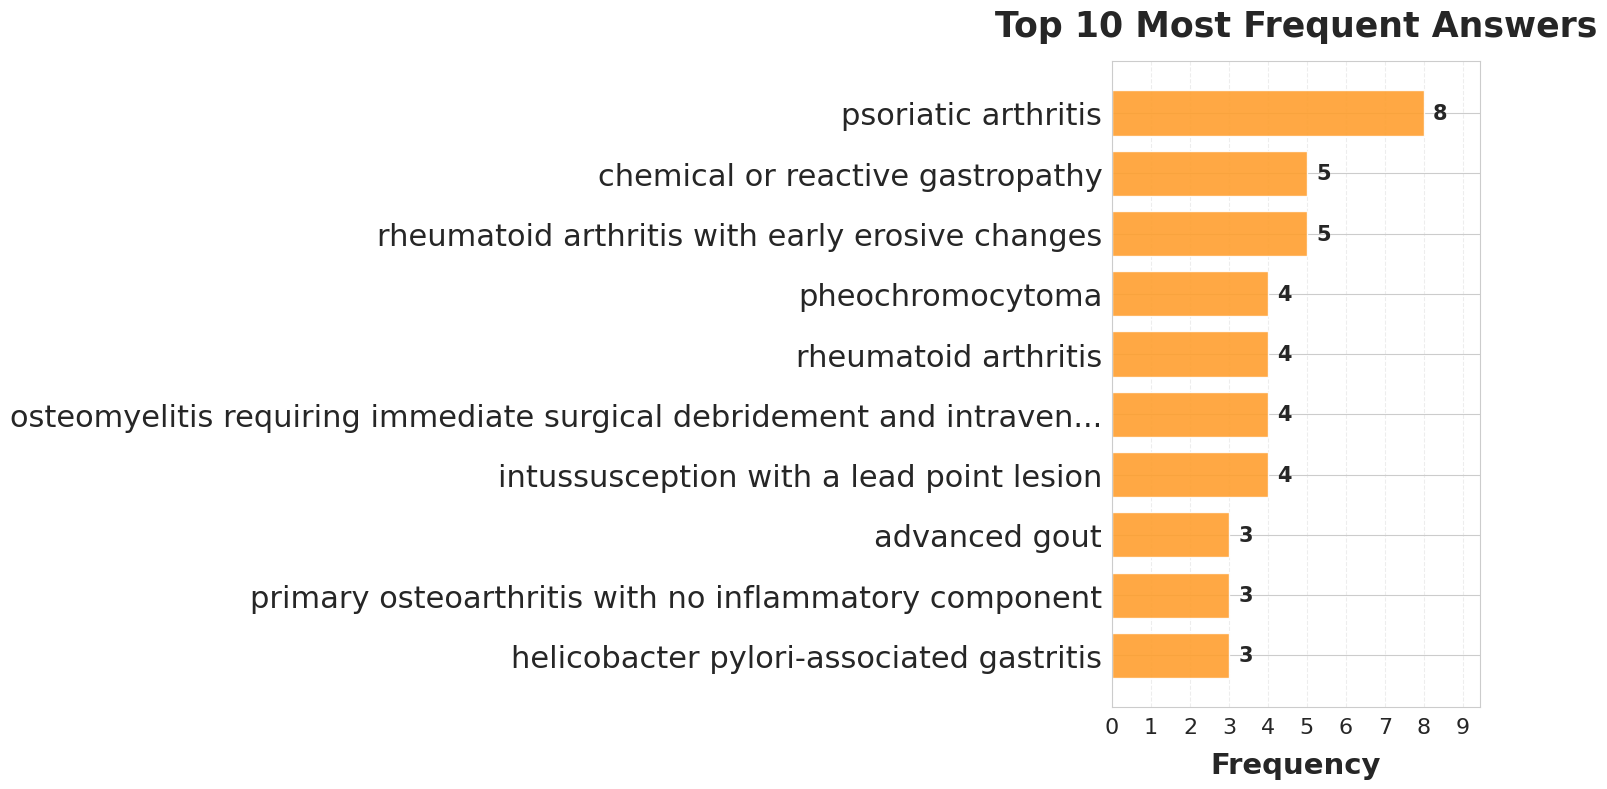

In [10]:
# ============================================================
# FIGURE 6: TOP 10 MOST FREQUENT ANSWERS
# MedFrameVQA
# ============================================================

from matplotlib.ticker import MaxNLocator

# Normalize the answers
normalized_answers = (
    df['answer']
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Remove empty answers
normalized_answers = normalized_answers[
    normalized_answers != ''
]

# Get the 10 most frequent answers
top_answers = (
    normalized_answers
    .value_counts()
    .head(10)
)

# Shorten excessively long answers
answer_labels = [
    answer if len(answer) <= 70
    else answer[:67] + '...'
    for answer in top_answers.index
]

# Positions to keep the bars close together
positions = np.arange(len(top_answers)) * 0.60

# Create figure
fig, ax = plt.subplots(figsize=(15, 8))

bars = ax.barh(
    positions,
    top_answers.values,
    color='#FF9F2F',
    height=0.45,
    alpha=0.9
)

# Place the answers on the Y-axis
ax.set_yticks(positions)

ax.set_yticklabels(
    answer_labels,
    fontsize=22
)

ax.invert_yaxis()

# Display the value at the end of each bar
offset = max(top_answers.values) * 0.03

for bar, value in zip(bars, top_answers.values):
    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f'{value}',
        va='center',
        ha='left',
        fontsize=15,
        fontweight='bold'
    )

ax.set_title(
    'Top 10 Most Frequent Answers',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel('')

ax.tick_params(
    axis='x',
    labelsize=16
)

# Display only integers
ax.xaxis.set_major_locator(
    MaxNLocator(integer=True)
)

ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.35
)

# Leave space to display the values
ax.set_xlim(
    0,
    max(top_answers.values) * 1.18
)

plt.tight_layout()
plt.show()

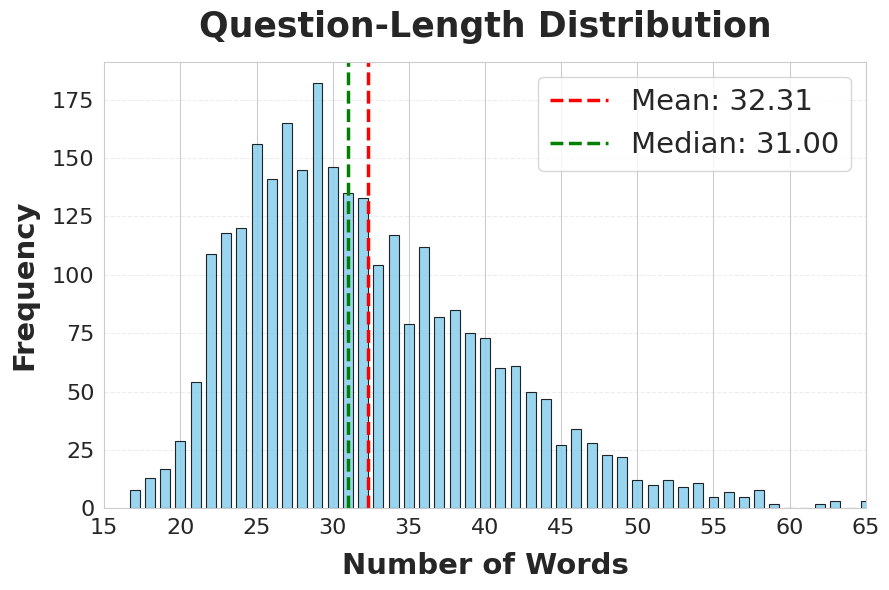

In [11]:
# ============================================================
# FIGURE 7: QUESTION-LENGTH DISTRIBUTION
# MedFrameQA
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Prepare the questions
questions = (
    df['question']
    .fillna('')
    .astype(str)
    .str.strip()
)

# Remove empty questions
questions = questions[questions != '']

# Calculate the number of words
question_lengths = (
    questions
    .str.split()
    .str.len()
)

question_lengths = question_lengths[
    question_lengths > 0
]

# Calculate the mean and median
mean = question_lengths.mean()
median = question_lengths.median()

# Calculate the frequency of each length
frequencies = (
    question_lengths
    .value_counts()
    .sort_index()
)

# Include lengths without records
full_range = range(
    int(question_lengths.min()),
    int(question_lengths.max()) + 1
)

frequencies = frequencies.reindex(
    full_range,
    fill_value=0
)

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    frequencies.index,
    frequencies.values,
    width=0.65,
    color='#87CEEB',
    edgecolor='black',
    linewidth=0.8,
    alpha=0.85
)

# Mean
ax.axvline(
    mean,
    color='red',
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: {mean:.2f}'
)

# Median
ax.axvline(
    median,
    color='green',
    linestyle='--',
    linewidth=2.5,
    label=f'Median: {median:.2f}'
)

ax.set_title(
    'Question-Length Distribution',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Number of Words',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.tick_params(
    axis='both',
    labelsize=16
)

# Display the X-axis starting at 15 words
upper_limit = int(question_lengths.max()) + 1

# Display the X-axis from 15 to 65 words
ax.set_xlim(15, 65)

ax.set_xticks(
    np.arange(15, 66, 5)
)



ax.legend(
    fontsize=21,
    loc='upper right',
    frameon=True
)

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.35
)

plt.tight_layout()
plt.show()

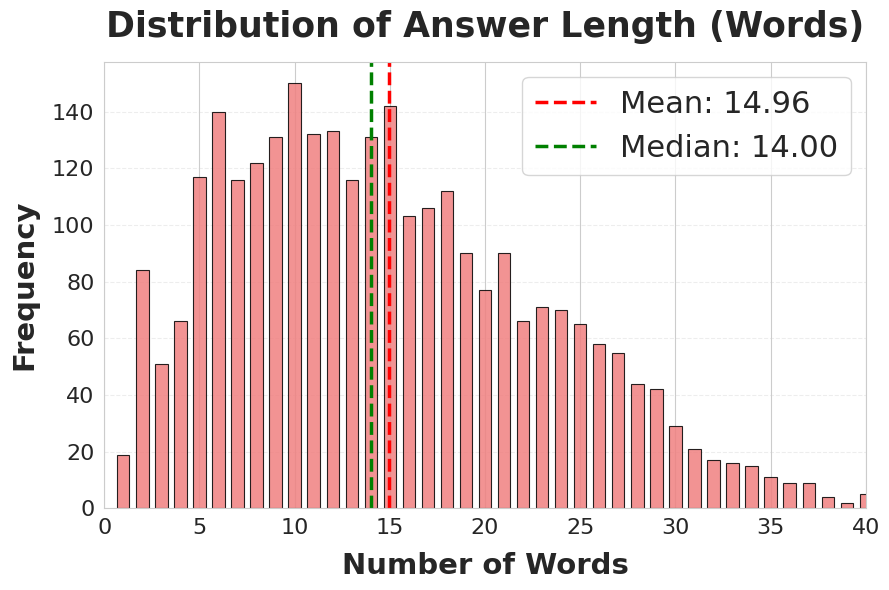

In [12]:
# ============================================================
# FIGURE 8: DISTRIBUTION OF ANSWER LENGTH
# MedFrameVQA
# ============================================================

# Prepare the answers
answers = (
    df['answer']
    .fillna('')
    .astype(str)
    .str.strip()
)

# Remove empty answers
answers = answers[
    answers != ''
]

# Calculate the number of words
answer_lengths = (
    answers
    .str.split()
    .str.len()
)

# Remove invalid lengths
answer_lengths = answer_lengths[
    answer_lengths > 0
]

# Calculate the mean and median
mean = answer_lengths.mean()
median = answer_lengths.median()

# Calculate frequencies
frequencies = (
    answer_lengths
    .value_counts()
    .sort_index()
)

# Include lengths without records
full_range = range(
    int(answer_lengths.min()),
    int(answer_lengths.max()) + 1
)

frequencies = frequencies.reindex(
    full_range,
    fill_value=0
)

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    frequencies.index,
    frequencies.values,
    width=0.65,
    color='#F08080',
    edgecolor='black',
    linewidth=0.8,
    alpha=0.85
)

# Mean line
ax.axvline(
    mean,
    color='red',
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: {mean:.2f}'
)

# Median line
ax.axvline(
    median,
    color='green',
    linestyle='--',
    linewidth=2.5,
    label=f'Median: {median:.2f}'
)

ax.set_title(
    'Distribution of Answer Length (Words)',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Number of Words',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.tick_params(
    axis='both',
    labelsize=16
)

# Display the X-axis from 0 to 40 words
ax.set_xticks(
    np.arange(0, 41, 5)
)

ax.set_xlim(
    0,
    40
)

ax.legend(
    fontsize=22,
    loc='upper right',
    frameon=True
)

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.35
)

plt.tight_layout()
plt.show()